<a href="https://colab.research.google.com/github/alifiaganjaraharja/IMDB-Project/blob/main/%5BIMDb%5D%20-%20Analysis%20with%20Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

Movie1 = pd.read_csv('/content/sample_data/IMDb_Dataset.csv')
Movie2 = pd.read_csv('/content/sample_data/IMDb_Dataset_2.csv')

Movie1.head()

,Title,IMDb Rating,Year,Certificates,Genre,Director,Star Cast,MetaScore,Duration (minutes)
0,Gladiator,8.5,2000,R,Action,Ridley Scott,David FranzoniJohn LoganWilliam Nicholson,67.0,155.0
1,Mission: Impossible - Dead Reckoning Part One,7.7,2023,PG-13,Action,Christopher McQuarrie,Tom CruiseHayley AtwellVing Rhames,81.0,163.0
2,Rebel Moon - Part Two: The Scargiver,5.2,2024,PG-13,Action,Zack Snyder,Zack SnyderKurt JohnstadShay Hatten,35.0,122.0
3,Inglourious Basterds,8.4,2009,R,Adventure,Quentin Tarantino,Brad PittDiane KrugerEli Roth,69.0,153.0
4,Borderlands,7.1,2024,R,Action,Eli Roth,Eli RothJoe Crombie,66.9,116.3


In [13]:
Movie2.head()

,Title,IMDb Rating,Year,Certificates,Genre,Director,Star Cast,MetaScore,Poster-src,Duration (minutes)
0,End of the Spear,6.8,2005,PG-13,Adventure,Jim Hanon,Louie LeonardoChad AllenJack Guzman,45.0,https://m.media-amazon.com/images/M/MV5BMTYxOT...,108.0
1,Elvira Madigan,7.0,1967,PG,Biography,Bo Widerberg,Pia DegermarkThommy BerggrenLennart Malmer,66.0,https://m.media-amazon.com/images/M/MV5BMmY2Nj...,91.0
2,The Kid Stays in the Picture,7.3,2002,R,Documentary,Nanette Burstein,Robert EvansEddie AlbertPeter Bart,75.0,https://m.media-amazon.com/images/M/MV5BZjhiZm...,93.0
3,It Ain't Over,8.2,2022,PG,Documentary,Sean Mullin,Andy AndresRoger AngellMarty Appel,79.0,https://m.media-amazon.com/images/M/MV5BZWViYW...,99.0
4,Mahler,7.0,1974,PG,Biography,Ken Russell,Robert PowellGeorgina HaleLee Montague,66.0,https://m.media-amazon.com/images/M/MV5BYzY4Mz...,115.0


In [14]:
#Check all of the information on both dataset Movie1 & Movie2
print("Dataset 1 columns:", Movie1.columns.tolist())
print("Dataset 2 columns:", Movie2.columns.tolist())
Movie1.info()
Movie2.info()

Dataset 1 columns: ['Title', 'IMDb Rating', 'Year', 'Certificates', 'Genre', 'Director', 'Star Cast', 'MetaScore', 'Duration (minutes)']
Dataset 2 columns: ['Title', 'IMDb Rating', 'Year', 'Certificates', 'Genre', 'Director', 'Star Cast', 'MetaScore', 'Poster-src', 'Duration (minutes)']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Title               400 non-null    object 
 1   IMDb Rating         400 non-null    float64
 2   Year                400 non-null    int64  
 3   Certificates        400 non-null    object 
 4   Genre               400 non-null    object 
 5   Director            400 non-null    object 
 6   Star Cast           400 non-null    object 
 7   MetaScore           400 non-null    float64
 8   Duration (minutes)  400 non-null    float64
dtypes: float64(3), int64(1), object(5)
memory usage: 28.3+ KB
<class

In [15]:
# standardizing all of the column names of both dataset
def clean_column_names(df):
    df.columns = (
        df.columns
        .str.strip()                          # Remove leading/trailing spaces
        .str.replace(" ", "_", regex=False)   # Replace spaces with underscores
        .str.replace("-", "_", regex=False)   # Replace hyphens with underscores
        .str.replace("(", "", regex=False)    # Remove opening parenthesis
        .str.replace(")", "", regex=False)    # Remove closing parenthesis
    )
    return df

Movie1 = clean_column_names(Movie1)
Movie2 = clean_column_names(Movie2)

print("Cleaned Movie1 columns:", Movie1.columns.tolist())
print("Cleaned Movie2 columns:", Movie2.columns.tolist())

Cleaned Movie1 columns: ['Title', 'IMDb_Rating', 'Year', 'Certificates', 'Genre', 'Director', 'Star_Cast', 'MetaScore', 'Duration_minutes']
Cleaned Movie2 columns: ['Title', 'IMDb_Rating', 'Year', 'Certificates', 'Genre', 'Director', 'Star_Cast', 'MetaScore', 'Poster_src', 'Duration_minutes']


In [16]:
# Analysis 1: Top 10 Directors by Total Movies
director_rank = (
    Movie2.groupby("Director", as_index=False)
    .agg(TotalMovies=("Title", "count"))
)

director_rank["DirectorRank"] = (
    director_rank["TotalMovies"]
    .rank(method="min", ascending=False)
    .astype(int)
)

top_10_directors = (
    director_rank.sort_values(by=["DirectorRank", "Director"])
    .head(10)
)

print("--- Top 10 Directors ---")
print(top_10_directors.to_string(index=False))

--- Top 10 Directors ---
         Director  TotalMovies  DirectorRank
     Ridley Scott           23             1
 Steven Spielberg           19             2
  Martin Scorsese           14             3
   Clint Eastwood           12             4
     Oliver Stone           12             4
Christopher Nolan           11             6
    Peter Jackson           10             7
    Robert Eggers           10             7
  Robert Zemeckis           10             7
       Ron Howard           10             7


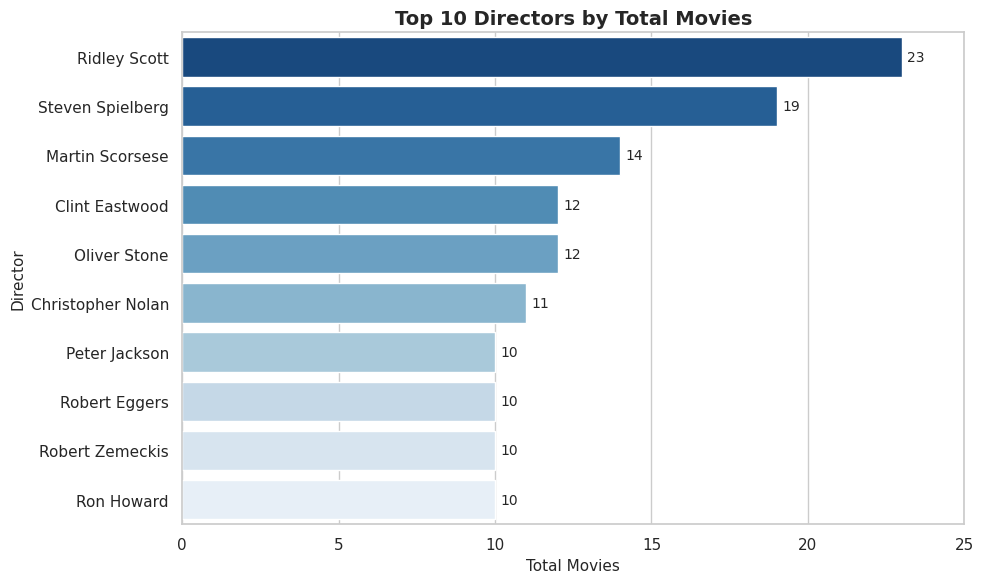

In [25]:
# Visualization
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=top_10_directors,
    x="TotalMovies",
    y="Director",
    hue="Director",
    palette="Blues_r",
    legend=False
)

ax.set_title("Top 10 Directors by Total Movies", fontsize=14, fontweight="bold")
ax.set_xlabel("Total Movies", fontsize=11)
ax.set_ylabel("Director", fontsize=11)

# Add exact movie count labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, padding=4, fontsize=10)

plt.xlim(0, top_10_directors["TotalMovies"].max() + 2)
plt.tight_layout()
plt.savefig("top_10_directors.png", dpi=300)
plt.show()

At first, I assumed that there is a correlation between the total number of movies produces by a director and the IMDb rating.

My hypothesis is: **The more movies a director produces, the higher the IMDb rating they received.**

To determine if my hypothesis was correct, I calculated the correlation coefficient between these two metrics (total movies and average IMDB rating).

In [17]:
# Analysis 2: Director Movie Count vs. Average IMDb Rating (Correlation)
director_stats = (
    Movie2.groupby("Director", as_index=False)
    .agg(
        TotalMovies=("Title", "count"),
        AvgRating=("IMDb_Rating", "mean")
    )
)

# Calculate Pearson correlation coefficient and p-value
r_value, p_value = stats.pearsonr(
    director_stats["TotalMovies"],
    director_stats["AvgRating"]
)

print(f"Pearson Correlation (r): {r_value:.3f}")
print(f"P-value: {p_value:.4e}")

Pearson Correlation (r): 0.163
P-value: 6.6976e-14


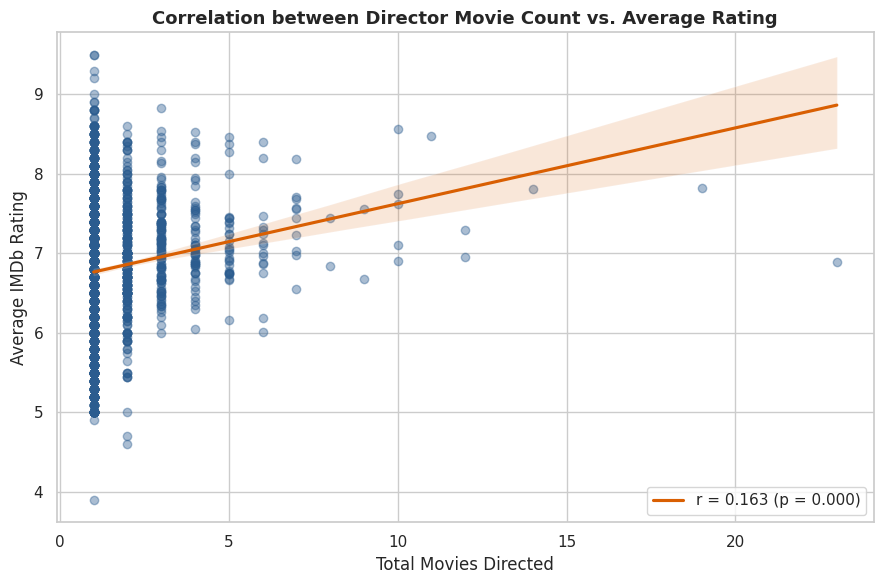

In [30]:
# Visualization

fig, ax = plt.subplots(figsize=(9, 6))

# Regression plot for Director Movie Count vs. Average Rating
sns.regplot(
    data=director_stats,
    x="TotalMovies",
    y="AvgRating",
    scatter_kws={"alpha": 0.4, "color": "#2b5c8f"},
    line_kws={"color": "#d95f02", "label": f"r = {r_value:.3f} (p = {p_value:.3f})"},
    ax=ax
)

ax.set_title("Correlation between Director Movie Count vs. Average Rating", fontsize=13, fontweight="bold")
ax.set_xlabel("Total Movies Directed")
ax.set_ylabel("Average IMDb Rating")
ax.legend()

plt.tight_layout()
plt.show()

Turned out, the result of the Correlation Coefficient number is r = 0.163 which indicates that **there is a slight positive correlation, but it is very weak, suggesting that the number of movies a director produces does not have a significant impact on the average IMDB rating of their movies.**

There may be other factors that affect the higher ratings some directors receive, which could lead to further potential analyses.

In [18]:
# Analysis 3: Top 10 Movie Genres (2019–2024)
# Filter for releases between 2019 and 2024 and remove duplicate rows
recent_movies = (
    Movie2[Movie2["Year"].between(2019, 2024)]
    .drop_duplicates(subset=["Title", "Year", "Genre"])
    .copy()
)

# Split multi-genre strings if applicable, otherwise group directly
recent_movies["Genre"] = recent_movies["Genre"].str.split(",")
exploded_genres = recent_movies.explode("Genre")
exploded_genres["Genre"] = exploded_genres["Genre"].str.strip()

# Rank genres based solely on average IMDb rating
top_10_genres = (
    exploded_genres.groupby("Genre", as_index=False)
    .agg(AvgRating=("IMDb_Rating", "mean"))
    .sort_values(by="AvgRating", ascending=False)
    .head(10)
)

top_10_genres["AvgRating"] = top_10_genres["AvgRating"].round(2)
top_10_genres["GenreRank"] = (
    top_10_genres["AvgRating"]
    .rank(method="min", ascending=False)
    .astype(int)
)

print("--- Top 10 Genres by Average Rating (2019–2024) ---")
print(top_10_genres.to_string(index=False))

--- Top 10 Genres by Average Rating (2019–2024) ---
      Genre  AvgRating  GenreRank
Documentary       7.52          1
  Adventure       7.22          2
  Animation       7.00          3
    History       6.90          4
  Biography       6.90          4
     Sci-Fi       6.88          6
      Drama       6.72          7
     Action       6.70          8
    Fantasy       6.68          9
     Comedy       6.66         10


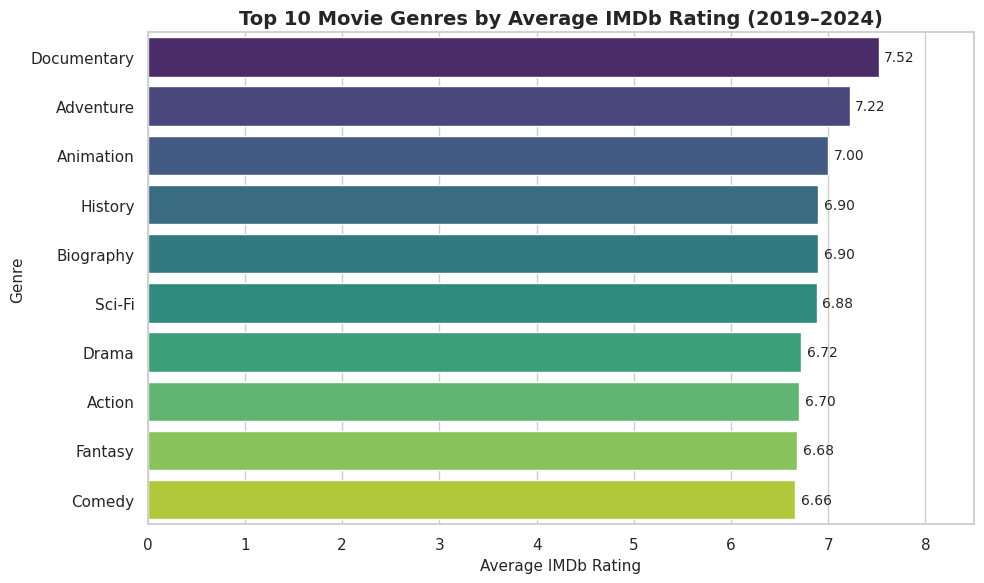

In [33]:
# Visualization
# Plot 2: Horizontal Bar Chart of Top 10 Genres (2019–2024)
fig, ax = plt.subplots(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.barplot(
    data=top_10_genres,
    x="AvgRating",
    y="Genre",
    hue="Genre",
    palette="viridis",
    legend=False,
    ax=ax
)

ax.set_title("Top 10 Movie Genres by Average IMDb Rating (2019–2024)", fontsize=14, fontweight="bold")
ax.set_xlabel("Average IMDb Rating", fontsize=11)
ax.set_ylabel("Genre", fontsize=11)

# Display exact 2-decimal average ratings at the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4, fontsize=10)

ax.set_xlim(0, 8.5)
plt.tight_layout()
plt.savefig("top_10_genres_avg_rating.png", dpi=300)
plt.show()

In [19]:
# Analysis 4: Top Rated Movies (IMDb Rating >= 8.0)
top_rated_movies = (
    Movie2[Movie2["IMDb_Rating"] >= 8.0]
    .sort_values(by="IMDb_Rating", ascending=False)
)

print(f"\nTotal movies: {len(Movie2)} | Top-rated (>= 8.0): {len(top_rated_movies)}")
print(top_rated_movies[["Title", "Director", "Year", "IMDb_Rating"]].head(10).to_string(index=False))


Total movies: 3173 | Top-rated (>= 8.0): 338
                                        Title             Director  Year  IMDb_Rating
                           The People's Story      Steven Scaffidi  2000          9.5
                              Marty's Project          Andrew Kent  2010          9.5
                     The Shawshank Redemption       Frank Darabont  1994          9.3
                                Loving Carmen          Nayo Titzin  2016          9.3
                             Fuga dalla Morte      Michael Righini  2023          9.2
                                The Godfather Francis Ford Coppola  1972          9.2
The Lord of the Rings: The Return of the King        Peter Jackson  2003          9.0
                             Schindler's List     Steven Spielberg  1993          9.0
                             Schindler's List     Steven Spielberg  1993          9.0
                Fast Shark III: Fastest Shark     Kailer Scopacasa  2023          9.0


In [23]:
import re

# Analysis 5: Actor-Director Collaborations & Top Star Cast
# 1. Deduplicate unique movies so multi-genre rows aren't double-counted
unique_movies = Movie2.drop_duplicates(subset=["Title", "Year", "Director"]).copy()

# 2. Smart regex splitter for concatenated names (preserves Mc, Mac, Di, De, La, Van, Von)
def parse_cast(cast_str):
    if pd.isna(cast_str):
        return []
    split_str = re.sub(
        r'(?<!\bMc)(?<!\bMac)(?<!\bDi)(?<!\bDe)(?<!\bLa)(?<!\bVan)(?<!\bVon)(?<=[a-z])(?=[A-Z])',
        '|',
        str(cast_str)
    )
    return [name.strip() for name in split_str.split('|') if name.strip()]

unique_movies["Actor_List"] = unique_movies["Star_Cast"].apply(parse_cast)

# Explode list into one row per movie-cast member pair
movie_actors = unique_movies.explode("Actor_List").rename(columns={"Actor_List": "Actor"})

# Exclude rows where the Director is listed in Star_Cast (self-credits / writer-directors)
actor_only = movie_actors[movie_actors["Actor"] != movie_actors["Director"]].copy()

# --- PART A: Top 10 Lead Actors in Top-Rated Films (IMDb_Rating >= 8.0) ---
top_rated_actors = (
    actor_only[actor_only["IMDb_Rating"] >= 8.0]
    .groupby("Actor", as_index=False)
    .agg(
        TopRatedMovies=("Title", "count"),
        AvgRating=("IMDb_Rating", "mean"),
        SampleTitles=("Title", lambda x: ", ".join(list(x)[:3]))
    )
    .sort_values(by=["TopRatedMovies", "AvgRating"], ascending=[False, False])
    .head(10)
)
top_rated_actors["AvgRating"] = top_rated_actors["AvgRating"].round(2)

print("--- Top 10 Cast Members in Top-Rated Films (IMDb >= 8.0) ---")
print(top_rated_actors.to_string(index=False))

--- Top 10 Cast Members in Top-Rated Films (IMDb >= 8.0) ---
            Actor  TopRatedMovies  AvgRating                                                                                                                            SampleTitles
 Daniel Radcliffe              14       8.29                                    Super/Man: The Christopher Reeve Story, Harry Potter and the Deathly Hallows: Part 2, Rabbids Escape
      Emma Watson              14       8.29                                    Super/Man: The Christopher Reeve Story, Harry Potter and the Deathly Hallows: Part 2, Rabbids Escape
     Rupert Grint              14       8.29                                    Super/Man: The Christopher Reeve Story, Harry Potter and the Deathly Hallows: Part 2, Rabbids Escape
Leonardo DiCaprio               5       8.42                                                                                 Catch Me If You Can, The Wolf of Wall Street, Inception
       Matt Damon               5 

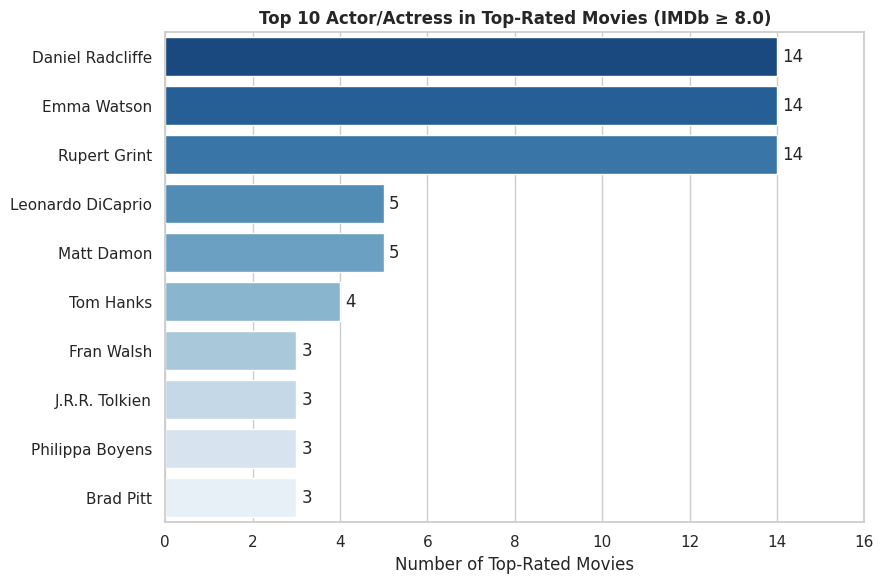

In [36]:
# Visualization

fig, ax = plt.subplots(figsize=(9, 6))
sns.set_theme(style="whitegrid")

# Chart 1: Top Cast in Top-Rated Movies
sns.barplot(
    data=top_rated_actors,
    x="TopRatedMovies",
    y="Actor",
    hue="Actor",
    palette="Blues_r",
    legend=False,
    ax=ax
)

ax.set_title("Top 10 Actor/Actress in Top-Rated Movies (IMDb ≥ 8.0)", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Top-Rated Movies")
ax.set_ylabel("")

for container in ax.containers:
    ax.bar_label(container, padding=4)

ax.set_xlim(0, top_rated_actors["TopRatedMovies"].max() + 2)
plt.tight_layout()
plt.show()

In [24]:
# --- PART B: Most Frequent Director-Actor Collaborations ---
director_actor_pairs = (
    actor_only.groupby(["Director", "Actor"], as_index=False)
    .agg(
        Collaborations=("Title", "count"),
        AvgRating=("IMDb_Rating", "mean"),
        Movies=("Title", lambda x: ", ".join(list(x)[:3]))
    )
    .query("Collaborations >= 3")
    .sort_values(by=["Collaborations", "AvgRating"], ascending=[False, False])
    .head(10)
)
director_actor_pairs["AvgRating"] = director_actor_pairs["AvgRating"].round(2)
director_actor_pairs["Pair"] = director_actor_pairs["Director"] + " & " + director_actor_pairs["Actor"]

print("\n--- Top 10 Director-Cast Collaborations ---")
print(director_actor_pairs[["Director", "Actor", "Collaborations", "AvgRating", "Movies"]].to_string(index=False))


--- Top 10 Director-Cast Collaborations ---
        Director             Actor  Collaborations  AvgRating                                                                                                                          Movies
   Peter Jackson        Fran Walsh               4       8.62       The Hobbit: The Desolation of Smaug, The Lord of the Rings: The Two Towers, The Lord of the Rings: The Return of the King
   Peter Jackson   Philippa Boyens               4       8.62       The Hobbit: The Desolation of Smaug, The Lord of the Rings: The Two Towers, The Lord of the Rings: The Return of the King
 Martin Scorsese Leonardo DiCaprio               4       7.95                                                                The Aviator, The Wolf of Wall Street, Killers of the Flower Moon
Steven Spielberg         Tom Hanks               4       7.88                                                                                  The Post, Catch Me If You Can, Bridge of Spies
     

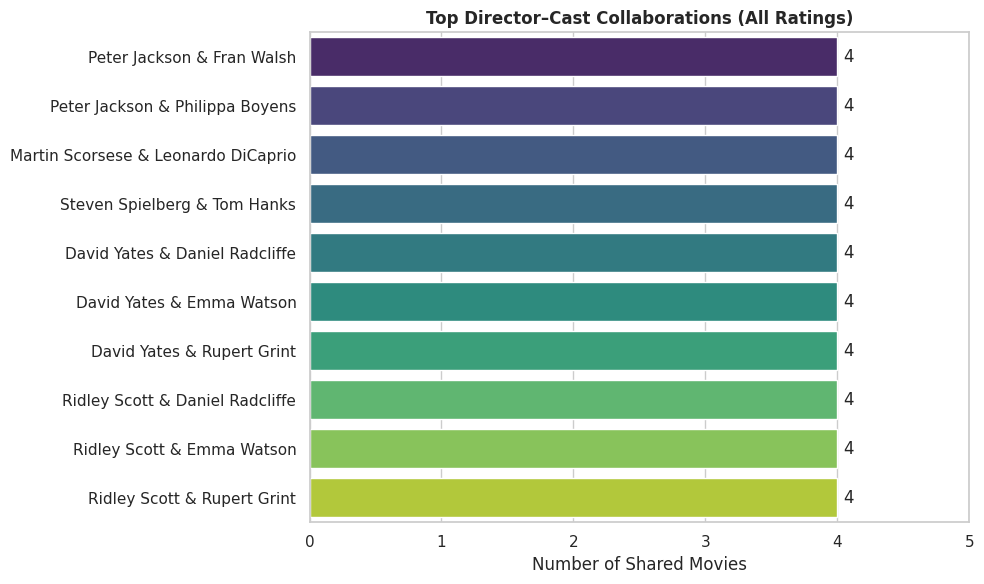

In [38]:
# Visualization
# Chart 2: Top Director-Cast Collaborations
fig, ax = plt.subplots(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.barplot(
    data=director_actor_pairs,
    x="Collaborations",
    y="Pair",
    hue="Pair",          # Assign the y-axis variable to hue
    palette="viridis",
    legend=False,        # Hide redundant legend
    ax=ax
)

ax.set_title("Top Director–Cast Collaborations (All Ratings)", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Shared Movies")
ax.set_ylabel("")

for container in ax.containers:
    ax.bar_label(container, padding=4)

ax.set_xlim(0, director_actor_pairs["Collaborations"].max() + 1)
plt.tight_layout()
plt.show()